# FIMCAP — Experiment 11: Component Ablation & Robustness Validation

**Purpose:** fixed-parameter, paired factorial ablation of the three components selected in Experiment 10: uncertainty margin (0.25), switching penalty (1.4), and critical-task bonus (10). No parameter search and no external dataset required.

**Scientific boundary:** synthetic latent capability is a *simulation oracle*, not verified UAV physical capability. This experiment tests internal decision behavior, **not** flight safety or novelty by itself.

**Important:** This notebook deliberately reuses the exact `make_world`, `allocate`, and `simulate` definitions and four holdout scenarios from Experiment 10, so comparisons remain interpretable. The additional robustness scenarios are **new model settings**, not real-world external validation. Because Experiment 10's holdout outcomes were already inspected, this is a follow-up confirmatory-style analysis **not an untouched test set**.

In [1]:
import os, json, zipfile
from itertools import product
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from IPython.display import display
SEED=20261025; T=80; N_UAV=5; N_TASK=5
REQ=np.array([78.,67.,55.,43.,32.]); VALUE=np.array([10.,8.,6.,4.,2.])
MARGIN=.25; PENALTY=1.4; CRITICAL_BONUS=10.
REPS_MAIN=60; REPS_ROBUST=40; N_BOOT=2000
SCENARIOS={'low_noise':(5.,0.),'moderate_noise':(12.,0.),'high_noise':(22.,0.),'moderate_pessimistic_shift':(18.,-13.)}
ROBUST_SCENARIOS={'severe_shift':(22.,-20.),'biased_optimism':(12.,12.),'very_high_noise':(30.,0.)}
OUT='/content/FIMCAP_Experiment_11_Results' if os.path.isdir('/content') else 'FIMCAP_Experiment_11_Results'
os.makedirs(OUT,exist_ok=True)
print('Output:',OUT)

Output: FIMCAP_Experiment_11_Results


## 1. Exact Experiment 10 simulation model

Each world provides hidden `cap`, noisy `obs`, and a declared uncertainty `sigma`. The allocator observes only `obs` and `sigma`. It never sees `cap`. The evaluation uses hidden `cap` to calculate unsafe assignments. As in Experiment 10, this is an idealized, stationary assignment model; no flight dynamics or task durations are simulated.

In [2]:
def make_world(seed,noise_sd,bias):
    rng=np.random.default_rng(seed)
    cap=np.empty((T,N_UAV)); cap[0]=rng.uniform(68,97,N_UAV)
    onset=rng.integers(12,52,N_UAV); rate=rng.uniform(.35,1.2,N_UAV)
    for t in range(1,T):
        cap[t]=np.clip(cap[t-1]+rng.normal(0,.65,N_UAV)-(t>=onset)*rate,0,100)
    obs=np.clip(cap+rng.normal(0,noise_sd,cap.shape)+bias,0,100)
    sigma=np.full_like(obs,noise_sd if bias==0 else noise_sd*.5)
    return cap,obs,sigma

def allocate(score,sigma,previous,margin,penalty,critical_bonus):
    effective=score-margin*sigma
    eligible=effective[:,None]>=REQ[None,:]
    values=VALUE.copy();values[0]+=critical_bonus
    utility=np.where(eligible,values[None,:]+.001*score[:,None],-1e5)
    if penalty:
        for j in range(N_TASK):
            if previous[j]>=0:
                utility[:,j]-=np.where(np.arange(N_UAV)==previous[j],0,penalty)
    payoff=np.vstack([utility,np.zeros((N_TASK,N_TASK))])
    rows,cols=linear_sum_assignment(-payoff)
    current=np.full(N_TASK,-1,int)
    for i,j in zip(rows,cols):
        if i<N_UAV and eligible[i,j]:current[j]=i
    return current

def simulate(world,margin,penalty,critical_bonus):
    cap,obs,sigma=world;prev=np.full(N_TASK,-1,int)
    unsafe=deferred=switches=critical=0;safe_utility=0.
    for t in range(T):
        curr=allocate(obs[t],sigma[t],prev,margin,penalty,critical_bonus)
        assigned=curr>=0;safe=np.zeros(N_TASK,bool)
        safe[assigned]=cap[t,curr[assigned]]>=REQ[assigned]
        unsafe+=int((assigned&~safe).sum());deferred+=int((~assigned).sum())
        switches+=int(((curr!=prev)&(curr>=0)&(prev>=0)).sum())
        safe_utility+=float(VALUE[safe].sum());critical+=int(safe[0]);prev=curr
    return {'unsafe_per_opportunity':unsafe/(T*N_TASK),
            'deferral_rate':deferred/(T*N_TASK),
            'safe_utility_ratio':safe_utility/(T*VALUE.sum()),
            'critical_safe_rate':critical/T,'switches':switches}
METRICS=['unsafe_per_opportunity','safe_utility_ratio','deferral_rate','critical_safe_rate','switches']
# Assert exact expected behavior and basic metric bounds
w=make_world(SEED,5.,0.)
assert all(0<=simulate(w,0,0,0)[k]<=1 for k in METRICS[:-1])
assert np.allclose(make_world(SEED,5.,0.)[0],w[0])
print('Model smoke test passed')

Model smoke test passed


## 2. Full 2×2×2 factorial ablation

Eight **fixed** policies isolate margin (`M`), switching penalty (`S`), and critical-task bonus (`C`). Every policy receives the **same** world in each replicate. We use Experiment 10 holdout seed family to reproduce its setting and an independent seed family for the three robustness scenarios. No optimization is performed.

**Caution:** factorial contrasts measure effects *within this simulator and parameter choice*, not causal effects in physical UAV operations.

In [3]:
CONFIGS={f'M{m}S{s}C{c}':(MARGIN*m,PENALTY*s,CRITICAL_BONUS*c)
         for m,s,c in product([0,1],repeat=3)}
assert len(CONFIGS)==8
records=[]
def run_suite(scenarios,reps,offset,cohort):
    for i,(scenario,(sd,bias)) in enumerate(scenarios.items()):
        for rep in range(reps):
            world=make_world(SEED+offset+10000*i+rep,sd,bias)
            for policy,config in CONFIGS.items():
                records.append({'cohort':cohort,'scenario':scenario,'rep':rep,'policy':policy,
                                'M':int(config[0]>0),'S':int(config[1]>0),'C':int(config[2]>0),
                                **simulate(world,*config)})
run_suite(SCENARIOS,REPS_MAIN,900000,'replication')
run_suite(ROBUST_SCENARIOS,REPS_ROBUST,1800000,'robustness')
runs=pd.DataFrame(records)
assert len(runs)==(4*REPS_MAIN+3*REPS_ROBUST)*8
runs.to_csv(os.path.join(OUT,'experiment11_runs.csv'),index=False)
summary=runs.groupby(['cohort','scenario','policy','M','S','C'],as_index=False)[METRICS].agg('mean')
summary.to_csv(os.path.join(OUT,'experiment11_summary.csv'),index=False)
print('Total simulations:',len(runs));display(summary.head(12).round(4))

Total simulations: 2880


,cohort,scenario,policy,M,S,C,unsafe_per_opportunity,safe_utility_ratio,deferral_rate,critical_safe_rate,switches
0,replication,high_noise,M0S0C0,0,0,0,0.1507,0.6672,0.1280,0.4977,239.6167
1,replication,high_noise,M0S0C1,0,0,1,0.1488,0.6706,0.1280,0.5094,238.9500
2,replication,high_noise,M0S1C0,0,1,0,0.1418,0.6807,0.1280,0.5273,114.8167
3,replication,high_noise,M0S1C1,0,1,1,0.1385,0.6862,0.1280,0.5448,114.0667
4,replication,high_noise,M1S0C0,1,0,0,0.1240,0.6515,0.1699,0.4869,220.0333
5,replication,high_noise,M1S0C1,1,0,1,0.1223,0.6544,0.1699,0.4969,218.9000
6,replication,high_noise,M1S1C0,1,1,0,0.1193,0.6583,0.1699,0.5021,121.9333
7,replication,high_noise,M1S1C1,1,1,1,0.1172,0.6616,0.1699,0.5098,121.4000
8,replication,low_noise,M0S0C0,0,0,0,0.0456,0.8017,0.0975,0.6438,238.3667
9,replication,low_noise,M0S0C1,0,0,1,0.0474,0.7986,0.0975,0.6337,239.4167


## 3. Paired component effects and 95% bootstrap confidence intervals

For each factor, compare `factor=1` against `factor=0` while holding the other two factors constant. The paired unit is a **world replicate**, not a time step. Bootstrap resamples world replicates. The eight policies are all run on the same worlds.

A component effect can vary depending on other components. We report all four matched contrasts per factor instead of averaging them into a misleading single effect.

In [4]:
rng=np.random.default_rng(SEED+1100)
def paired_effect(a,b,metric):
    # a and b must be aligned by scenario/rep
    x=a[metric].to_numpy()-b[metric].to_numpy()
    if len(x)<2:return float(np.mean(x)),np.nan,np.nan
    idx=rng.integers(0,len(x),size=(N_BOOT,len(x)))
    lo,hi=np.quantile(x[idx].mean(axis=1),[.025,.975])
    return float(x.mean()),float(lo),float(hi)
rows=[]
for (cohort,scenario),sub in runs.groupby(['cohort','scenario']):
    for factor in ['M','S','C']:
        others=[x for x in ['M','S','C'] if x!=factor]
        for x,y in product([0,1],repeat=2):
            base=sub[(sub[factor]==0)&(sub[others[0]]==x)&(sub[others[1]]==y)].sort_values('rep')
            treat=sub[(sub[factor]==1)&(sub[others[0]]==x)&(sub[others[1]]==y)].sort_values('rep')
            assert (base.rep.to_numpy()==treat.rep.to_numpy()).all()
            row={'cohort':cohort,'scenario':scenario,'factor':factor,
                 'other_1':others[0],'other_1_value':x,'other_2':others[1],'other_2_value':y,
                 'baseline_policy':base.policy.iloc[0],'treatment_policy':treat.policy.iloc[0]}
            for metric in METRICS:
                delta,lo,hi=paired_effect(treat,base,metric)
                row[metric+'_delta']=delta;row[metric+'_lo']=lo;row[metric+'_hi']=hi
            rows.append(row)
contrasts=pd.DataFrame(rows)
contrasts.to_csv(os.path.join(OUT,'experiment11_factorial_contrasts.csv'),index=False)
display(contrasts[(contrasts.cohort=='replication')&(contrasts.scenario=='high_noise')][['factor','baseline_policy','treatment_policy','unsafe_per_opportunity_delta','safe_utility_ratio_delta','critical_safe_rate_delta','switches_delta']].round(4))

,factor,baseline_policy,treatment_policy,unsafe_per_opportunity_delta,safe_utility_ratio_delta,critical_safe_rate_delta,switches_delta
0,M,M0S0C0,M1S0C0,-0.0267,-0.0157,-0.0108,-19.5833
1,M,M0S0C1,M1S0C1,-0.0264,-0.0162,-0.0125,-20.0500
2,M,M0S1C0,M1S1C0,-0.0225,-0.0223,-0.0252,7.1167
3,M,M0S1C1,M1S1C1,-0.0213,-0.0247,-0.0350,7.3333
4,S,M0S0C0,M0S1C0,-0.0089,0.0135,0.0296,-124.8000
5,S,M0S0C1,M0S1C1,-0.0102,0.0157,0.0354,-124.8833
6,S,M1S0C0,M1S1C0,-0.0047,0.0068,0.0152,-98.1000
7,S,M1S0C1,M1S1C1,-0.0052,0.0072,0.0129,-97.5000
8,C,M0S0C0,M0S0C1,-0.0019,0.0033,0.0117,-0.6667
9,C,M0S1C0,M0S1C1,-0.0032,0.0056,0.0175,-0.7500


## 4. Combined policy versus continuous baseline and key ablations

We compare `M1S1C1` to continuous `M0S0C0`, and to three leave-one-component-out ablations. This directly tests whether each component adds value **conditional on the other two**. Screening thresholds from Experiment 10 are shown only as descriptive criteria: risk improvement ≥2 percentage points, utility loss ≤3 points, deferral increase ≤10 points. These thresholds are not independent statistical tests.

In [5]:
comparisons={'continuous':'M0S0C0','without_margin':'M0S1C1',
             'without_switching':'M1S0C1','without_critical_bonus':'M1S1C0'}
rows=[]
for (cohort,scenario),sub in runs.groupby(['cohort','scenario']):
    target=sub[sub.policy=='M1S1C1'].sort_values('rep')
    for name,p in comparisons.items():
        baseline=sub[sub.policy==p].sort_values('rep')
        row={'cohort':cohort,'scenario':scenario,'comparison':name,'reference':p,'candidate':'M1S1C1'}
        for metric in METRICS:
            d,lo,hi=paired_effect(target,baseline,metric)
            row[metric+'_delta']=d;row[metric+'_lo']=lo;row[metric+'_hi']=hi
        row['screen_pass']=(row['unsafe_per_opportunity_delta']<=-.02 and
                            row['safe_utility_ratio_delta']>=-.03 and
                            row['deferral_rate_delta']<=.10)
        rows.append(row)
paired=pd.DataFrame(rows)
paired.to_csv(os.path.join(OUT,'experiment11_paired.csv'),index=False)
display(paired[paired.comparison=='continuous'][['cohort','scenario','unsafe_per_opportunity_delta','safe_utility_ratio_delta','deferral_rate_delta','critical_safe_rate_delta','switches_delta','screen_pass']].round(4))

,cohort,scenario,unsafe_per_opportunity_delta,safe_utility_ratio_delta,deferral_rate_delta,critical_safe_rate_delta,switches_delta,screen_pass
0,replication,high_noise,-0.0335,-0.0056,0.0419,0.0121,-118.2167,True
4,replication,low_noise,-0.0223,0.0191,0.0085,0.0304,-210.3333,True
8,replication,moderate_noise,-0.0344,0.0160,0.0224,0.0283,-160.5000,True
12,replication,moderate_pessimistic_shift,-0.0110,-0.0194,0.0267,-0.0235,-82.8833,False
16,robustness,biased_optimism,-0.0491,0.0635,0.0071,0.1216,-219.8000,True
20,robustness,severe_shift,-0.0094,-0.0269,0.0331,-0.0284,-51.1500,False
24,robustness,very_high_noise,-0.0324,-0.0200,0.0609,0.0241,-101.9000,True


## 5. Robustness and trade-off plots

The additional scenarios probe larger measurement noise and bias. The uncertainty `sigma` intentionally under-reports uncertainty in biased settings, as in Experiment 10; this is a model assumption, not an empirically calibrated error model. Interpretation must not claim external UAV generalization.

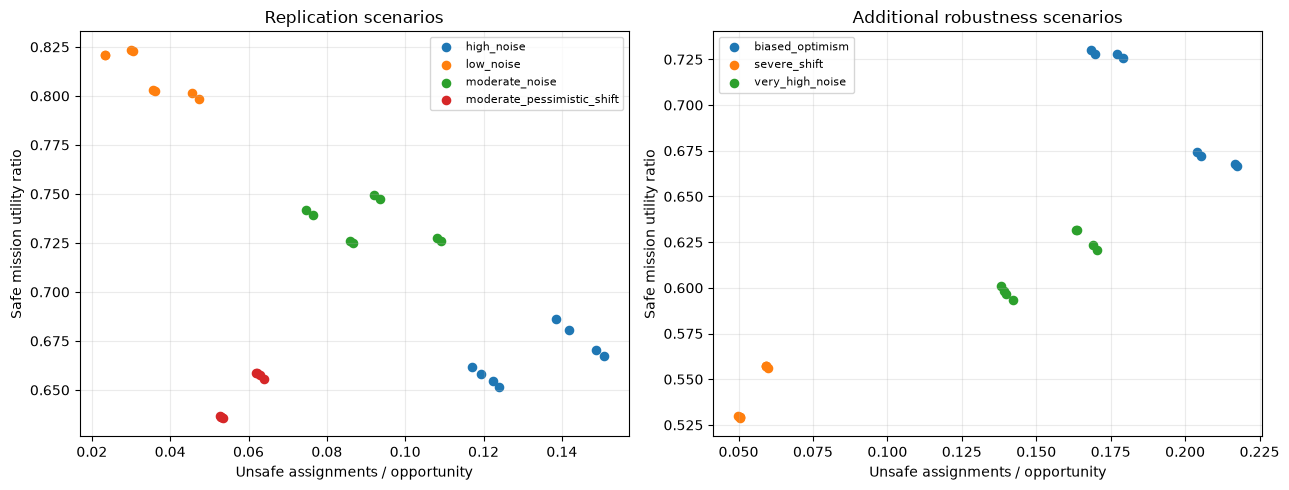

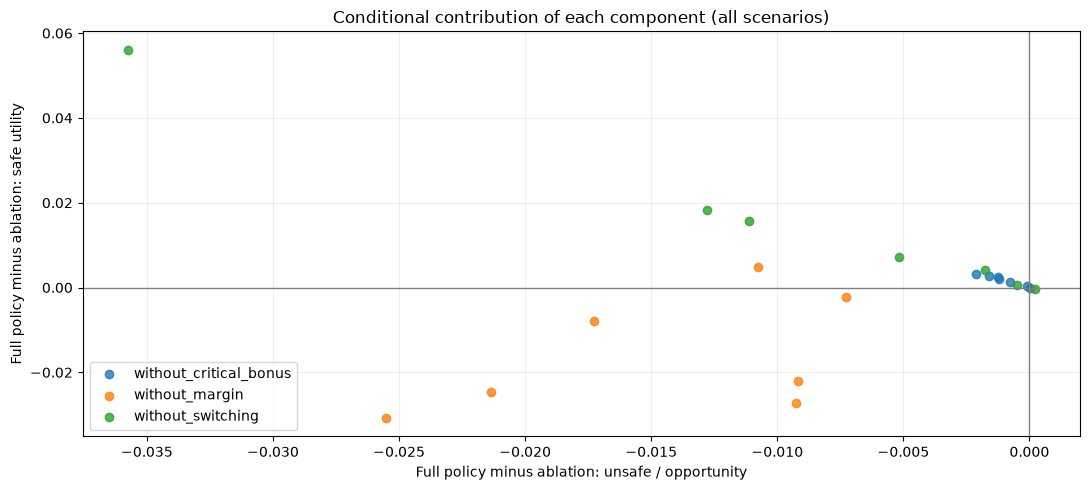

In [6]:
fig,axes=plt.subplots(1,2,figsize=(13,5))
for (cohort,scenario),sub in summary.groupby(['cohort','scenario']):
    if cohort=='replication':
        axes[0].scatter(sub.unsafe_per_opportunity,sub.safe_utility_ratio,label=scenario,s=35)
    else:
        axes[1].scatter(sub.unsafe_per_opportunity,sub.safe_utility_ratio,label=scenario,s=35)
for ax,title in zip(axes,['Replication scenarios','Additional robustness scenarios']):
    ax.set_title(title);ax.set_xlabel('Unsafe assignments / opportunity');ax.set_ylabel('Safe mission utility ratio')
    ax.grid(alpha=.25);ax.legend(fontsize=8)
plt.tight_layout();plt.savefig(os.path.join(OUT,'experiment11_tradeoffs.png'),dpi=170);plt.show()
# Plot conditional effects of removing components, in each scenario
subset=paired[paired.comparison!='continuous'].copy()
fig,ax=plt.subplots(figsize=(11,5))
for i,(name,g) in enumerate(subset.groupby('comparison')):
    ax.scatter(g.unsafe_per_opportunity_delta,g.safe_utility_ratio_delta,label=name,alpha=.8)
ax.axvline(0,color='gray',lw=1);ax.axhline(0,color='gray',lw=1)
ax.set_xlabel('Full policy minus ablation: unsafe / opportunity')
ax.set_ylabel('Full policy minus ablation: safe utility')
ax.set_title('Conditional contribution of each component (all scenarios)')
ax.legend();ax.grid(alpha=.2);plt.tight_layout()
plt.savefig(os.path.join(OUT,'experiment11_ablation.png'),dpi=170);plt.show()

## 6. Interpretation and reproducibility package

**Decision rules (interpretive, not publication guarantees):**

- A component has a useful contribution only if its removal worsens a relevant outcome and the effect is not fully explained by unacceptable loss of mission availability.
- If the full policy fails robustness settings, report the failure as a boundary of the method.
- Do not infer significance from multiple unadjusted bootstrap intervals; comparisons are exploratory and correlated.
- This synthetic experiment does not establish physically grounded UAV capability, calibrated health probabilities, or novelty relative to the literature.

The ZIP includes per-run metrics, summary, paired contrasts, plots, and assumptions. Please send it back for critical review.

In [7]:
meta={'experiment':'FIMCAP Experiment 11','seed':SEED,'steps':T,'uavs':N_UAV,'tasks':N_TASK,
      'requirements':REQ.tolist(),'task_values':VALUE.tolist(),
      'parameters_fixed':{'margin':MARGIN,'switching_penalty':PENALTY,'critical_bonus':CRITICAL_BONUS},
      'main_scenarios':SCENARIOS,'robustness_scenarios':ROBUST_SCENARIOS,
      'reps_main':REPS_MAIN,'reps_robustness':REPS_ROBUST,'bootstrap_replicates':N_BOOT,
      'note':'Same synthetic model as Experiment 10; replication seed family has already been inspected in Experiment 10. Not independent real-world validation.',
      'unsafe_denominator':'T * N_TASK (all opportunities)',
      'uncertainty_sigma':'noise_sd when bias=0, otherwise 0.5*noise_sd',
      'selection':'No tuning; full 2x2x2 fixed factorial ablation'}
with open(os.path.join(OUT,'experiment11_methodology.json'),'w') as f:json.dump(meta,f,indent=2)
zip_path='FIMCAP_Experiment_11_Results.zip'
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as z:
    for name in sorted(os.listdir(OUT)):
        z.write(os.path.join(OUT,name),arcname=name)
print('Created:',zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print('Download ZIP from Colab Files sidebar or current directory.')

Created: FIMCAP_Experiment_11_Results.zip
Download ZIP from Colab Files sidebar or current directory.
